<div dir="rtl" style="direction: rtl; text-align: right;">

# جلسه ۲ — پایتون برای عدد و تصویر: Data Model، NumPy، Matplotlib

جلسه‌ی قبل مبانی پایتون و کلاس را دیدیم. امروز:

| بخش | موضوع | کجای دیپ لرنینگ به درد می‌خورد؟ |
|---|---|---|
| ۱ | متدهای `__xxx__` (dunder) | چرا `a + b` و `model(x)` و `x[0, :]` کار می‌کنند |
| ۲ | iterator، generator، `Dataset` و `DataLoader` | خواندن داده batch به batch |
| ۳ | `with` و دکوراتور | `torch.no_grad()` |
| ۴ | NumPy | shape، broadcasting، ضرب ماتریسی |
| ۵ | Matplotlib | رسم loss، داده و تصویر |
| ۶ | پرسپترون از صفر | همان کد متلب درس، با پایتون |

جلسه‌ی ۳ (PyTorch) تقریباً همه‌ی این‌ها را دوباره، این بار روی تنسور، می‌بیند.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۱ — Data Model: پایتون چطور می‌فهمد `a + b` یعنی چه؟

جلسه‌ی قبل دو متد عجیب دیدیم: `__init__` و `__call__`. متدهایی که دو طرفشان `__` دارند (double underscore = **dunder**) را معمولاً شما مستقیم صدا نمی‌زنید؛ **خود پایتون** صدایشان می‌زند، وقتی از یک سینتکس خاص استفاده می‌کنید.

</div>

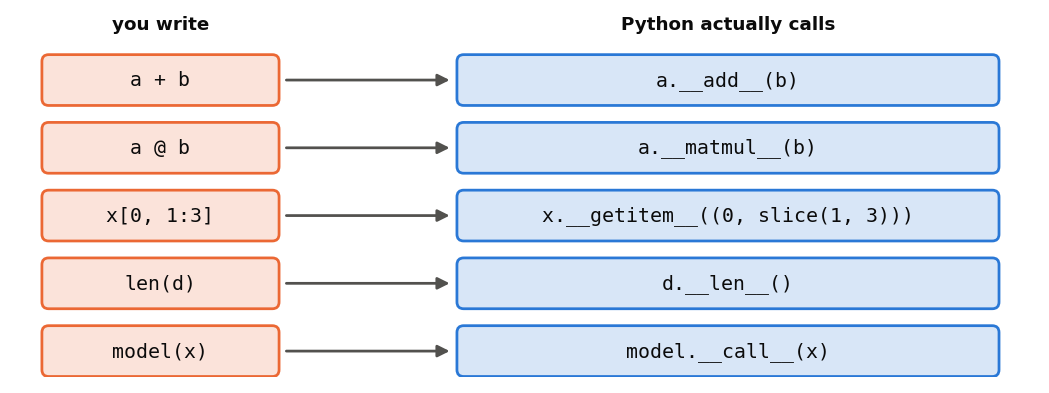

<div dir="rtl" style="direction: rtl; text-align: right;">

| شما می‌نویسید | پایتون صدا می‌زند |
|---|---|
| `obj = Cls(...)` | `Cls.__init__(obj, ...)` |
| `print(obj)` | `obj.__repr__()` |
| `a + b` ، `a * b` ، `a @ b` | `a.__add__(b)` ، `a.__mul__(b)` ، `a.__matmul__(b)` |
| `a == b` ، `a < b` | `a.__eq__(b)` ، `a.__lt__(b)` |
| `len(obj)` | `obj.__len__()` |
| `obj[i]` | `obj.__getitem__(i)` |
| `obj(x)` | `obj.__call__(x)` |
| `for x in obj` | `obj.__iter__()` |
| `with obj:` | `obj.__enter__()` و `obj.__exit__()` |

به این قرارداد می‌گویند **Data Model** پایتون. NumPy و PyTorch جادو نمی‌کنند؛ فقط همین متدها را برای آرایه و تنسور پیاده کرده‌اند.

حتی برای عددهای معمولی هم همین است:

</div>

In [ ]:
print(3 + 4)
print((3).__add__(4))         # exactly the same thing
print(len("hello"), "hello".__len__())

<div dir="rtl" style="direction: rtl; text-align: right;">

### یک «آرایه‌ی کوچک» از صفر

بیایید کلاس `Vector` بسازیم که مثل آرایه‌ی NumPy رفتار کند. هر متد را که اضافه می‌کنیم، یک سینتکس جدید برایش «روشن» می‌شود.

</div>

In [ ]:
class Vector:
    def __init__(self, values):
        self.values = list(values)

    def __repr__(self):                          # print(v)
        return f"Vector({self.values})"

    def __len__(self):                           # len(v)
        return len(self.values)

    def __getitem__(self, i):                    # v[i]
        return self.values[i]

    def __add__(self, other):                    # v + u
        return Vector(a + b for a, b in zip(self.values, other.values))

    def __mul__(self, k):                        # v * 3
        return Vector(a * k for a in self.values)

    def __matmul__(self, other):                 # v @ u  (dot product)
        return sum(a * b for a, b in zip(self.values, other.values))

v = Vector([1, 2, 3])
u = Vector([10, 20, 30])

print(v + u)
print(v * 3)
print(v @ u)
print(len(v), v[0], v[-1])

In [ ]:
# The operator and the dunder call are literally the same thing
print(v + u)
print(v.__add__(u))
print(Vector.__add__(v, u))

In [ ]:
# Without __add__, Python has no idea what `+` means for your class
class Empty:
    pass

try:
    Empty() + Empty()
except TypeError as e:
    print("TypeError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** `3 * v` کار نمی‌کند ولی `v * 3` کار می‌کند. چرا؟ (راهنمایی: `3 * v` یعنی `(3).__mul__(v)`، و `int` نمی‌داند `Vector` چیست.) راه‌حل پایتون متد `__rmul__` است. اضافه‌اش کنید.

</div>

In [ ]:
try:
    print(3 * v)
except TypeError as e:
    print("TypeError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

### داخل کروشه چه خبر است؟

در NumPy و PyTorch چیزهایی مثل `x[1:3, ::2]` یا `x[..., 0]` می‌نویسیم. این‌ها سینتکس ویژه‌ی NumPy نیستند. پایتون هر چیزی را که داخل `[]` باشد به یک شیء تبدیل می‌کند و به `__getitem__` می‌دهد. این کلاس فقط همان ورودی را نشان می‌دهد:

</div>

In [ ]:
class ShowKey:
    def __getitem__(self, key):
        return key

s = ShowKey()
print(s[0])
print(s[1:3])            # a slice object
print(s[1:3, ::2])       # a tuple of slices  <- this is "2D indexing"
print(s[..., 0])         # Ellipsis

<div dir="rtl" style="direction: rtl; text-align: right;">

### `__call__`: شیئی که مثل تابع صدا زده می‌شود

جلسه‌ی قبل در `Module` اسباب‌بازی دیدیم. فرق شیء callable با تابع معمولی این است که **حالت دارد** (وزن‌ها را در خودش نگه می‌دارد). همه‌ی لایه‌های PyTorch همین‌طورند: `nn.Linear(784, 128)` یک شیء می‌سازد (وزن‌ها ساخته می‌شوند) و بعد با `layer(x)` بارها صدایش می‌زنیم.

</div>

In [ ]:
class Scale:
    def __init__(self, factor):
        self.factor = factor             # state, kept between calls

    def __call__(self, x):
        return x * self.factor

double = Scale(2)
print(double(5), double(21))
print(callable(double), callable(5))

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۲ — iterator، generator و DataLoader

### پشت پرده‌ی حلقه‌ی `for`

حلقه‌ی `for` روی هر چیزی کار می‌کند که بشود از آن iterator گرفت. `for x in obj` در واقع این کارها را می‌کند:

1. `it = iter(obj)` ← یک iterator می‌گیرد (`obj.__iter__()`)
2. مدام `next(it)` صدا می‌زند
3. وقتی `StopIteration` آمد، حلقه تمام می‌شود

</div>

In [ ]:
it = iter([10, 20])
print(next(it))
print(next(it))
try:
    next(it)
except StopIteration:
    print("StopIteration -> the for loop ends here")

<div dir="rtl" style="direction: rtl; text-align: right;">

### generator: لیستی که تنبل است

اگر در comprehension به‌جای `[]` از `()` استفاده کنید، لیست ساخته **نمی‌شود**. یک **generator** ساخته می‌شود که عنصرها را **یکی‌یکی و فقط وقتی لازم شد** تولید می‌کند.

چرا مهم است؟ دیتاست ImageNet حدود ۱۵۰ گیگابایت است. نمی‌شود همه‌اش را یک‌جا در RAM ریخت. باید **batch به batch** ساخته و مصرف شود.

</div>

In [ ]:
import sys

big_list = [i ** 2 for i in range(1_000_000)]   # all values live in memory
big_gen = (i ** 2 for i in range(1_000_000))    # only the "recipe" lives in memory

print(f"list     : {sys.getsizeof(big_list):>10,} bytes")
print(f"generator: {sys.getsizeof(big_gen):>10,} bytes")
print(sum(big_gen))                             # still usable in a loop / sum

In [ ]:
# A generator is consumed once. The second pass is empty!
gen = (i * 10 for i in range(3))
print(list(gen))
print(list(gen))

<div dir="rtl" style="direction: rtl; text-align: right;">

**ربط به PyTorch:** `model.parameters()` یک generator است. باگ رایج: آن را در یک متغیر نگه می‌دارند، یک بار رویش حلقه می‌زنند (مثلاً برای شمردن پارامترها) و بعد همان را به optimizer می‌دهند، در حالی که دیگر خالی شده است.

### `yield`: نوشتن generator با تابع

تابعی که `yield` دارد با صدازدن اجرا نمی‌شود؛ یک generator برمی‌گرداند. هر بار که عنصر بعدی خواسته شود، تابع تا `yield` بعدی جلو می‌رود و **همان‌جا منتظر می‌ماند**.

</div>

In [ ]:
def countdown(n):
    print("  (start)")
    while n > 0:
        yield n                 # hand over one value and pause here
        n -= 1
    print("  (end)")

g = countdown(3)
print("nothing has run yet:", g)
for value in g:
    print(value)

<div dir="rtl" style="direction: rtl; text-align: right;">

تابع زیر در ۳ خط، هسته‌ی اصلی `DataLoader` است:

</div>

In [ ]:
def batches(data, batch_size):
    for start in range(0, len(data), batch_size):
        yield data[start:start + batch_size]

for batch in batches(list(range(10)), batch_size=4):
    print(batch)

<div dir="rtl" style="direction: rtl; text-align: right;">

### `Dataset` و `DataLoader` خودمان

در PyTorch دیتاست هر کلاسی است که دو سؤال را جواب بدهد:

- چند نمونه داری؟ ← `__len__`
- نمونه‌ی شماره‌ی `i` را بده ← `__getitem__`

و `DataLoader` روی دیتاست می‌چرخد، ترتیب را به‌هم می‌ریزد (shuffle) و batch می‌سازد (`__iter__` + `yield`).

</div>

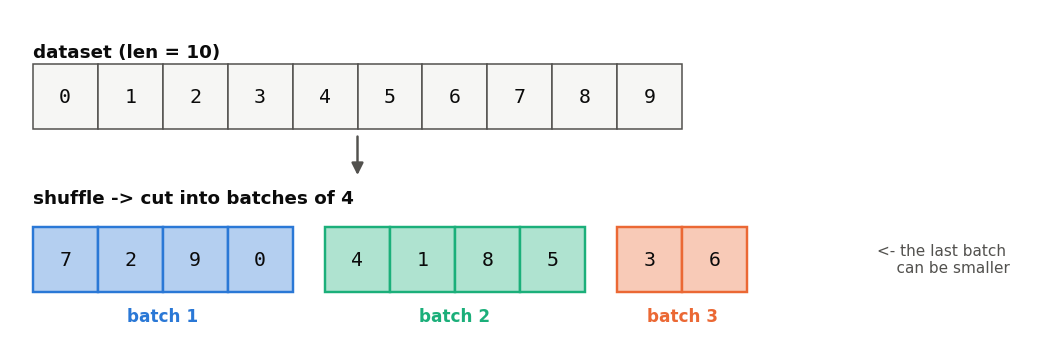

In [ ]:
import random

class MyDataset:
    def __init__(self, xs, ys):
        self.xs, self.ys = xs, ys

    def __len__(self):
        return len(self.xs)

    def __getitem__(self, i):
        return self.xs[i], self.ys[i]            # one (input, label) pair


class MyLoader:
    def __init__(self, dataset, batch_size, shuffle=False):
        self.dataset, self.batch_size, self.shuffle = dataset, batch_size, shuffle

    def __iter__(self):
        indices = list(range(len(self.dataset)))             # uses __len__
        if self.shuffle:
            random.shuffle(indices)
        for start in range(0, len(indices), self.batch_size):
            batch = [self.dataset[i] for i in indices[start:start + self.batch_size]]  # uses __getitem__
            xs = [x for x, _ in batch]
            ys = [y for _, y in batch]
            yield xs, ys


dataset = MyDataset(xs=[0.1, 0.2, 0.3, 0.4, 0.5], ys=[0, 0, 1, 1, 1])
print(len(dataset), dataset[2])

loader = MyLoader(dataset, batch_size=2, shuffle=True)
for epoch in range(2):
    print("epoch", epoch)
    for x, y in loader:                          # exactly the PyTorch syntax
        print("   x =", x, "| y =", y)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۳ — `with` و دکوراتور

### context manager

`with obj:` یعنی: موقع ورود `obj.__enter__()` و موقع خروج (حتی اگر خطا رخ بدهد) `obj.__exit__()` را صدا بزن. برای کارهایی است که «باز کردن و بستن» دارند؛ مثل فایل:

</div>

In [ ]:
with open("log.txt", "w") as f:          # the file is closed automatically at the end
    f.write("epoch 1 | loss 0.5\n")

with open("log.txt") as f:
    print(f.read())

<div dir="rtl" style="direction: rtl; text-align: right;">

`with torch.no_grad():` یعنی: موقع ورود محاسبه‌ی گرادیان را خاموش کن و موقع خروج به حالت قبل برگردان. نسخه‌ی اسباب‌بازی‌اش:

</div>

In [ ]:
GRAD_ENABLED = True

class no_grad:
    def __enter__(self):
        global GRAD_ENABLED
        self.previous = GRAD_ENABLED
        GRAD_ENABLED = False

    def __exit__(self, exc_type, exc_value, traceback):
        global GRAD_ENABLED
        GRAD_ENABLED = self.previous             # always restored

print("before:", GRAD_ENABLED)
with no_grad():
    print("inside:", GRAD_ENABLED)
print("after :", GRAD_ENABLED)

<div dir="rtl" style="direction: rtl; text-align: right;">

### دکوراتور

دکوراتور تابعی است که یک تابع می‌گیرد و نسخه‌ی «بسته‌بندی‌شده»‌ی آن را برمی‌گرداند. `@timer` بالای تابع یعنی `slow_sum = timer(slow_sum)`.

در PyTorch: `@torch.no_grad()` بالای تابع ارزیابی یعنی «این تابع را طوری بسته‌بندی کن که داخلش گرادیان حساب نشود».

</div>

In [ ]:
import time

def timer(func):
    def wrapper(*args, **kwargs):            # *args/**kwargs from session 1
        start = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} took {time.perf_counter() - start:.4f} s")
        return result
    return wrapper

@timer                       # same as: slow_sum = timer(slow_sum)
def slow_sum(n):
    return sum(i * i for i in range(n))

print(slow_sum(1_000_000))

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۴ — NumPy

شبکه‌ی عصبی یعنی ضرب و جمع ماتریس‌های بزرگ. NumPy کتابخانه‌ی آرایه‌های عددی پایتون است و **تنسور PyTorch تقریباً کپی همان است** (به‌اضافه‌ی GPU و گرادیان). هر چه اینجا یاد بگیرید، جلسه‌ی بعد عیناً به کار می‌آید.

### چرا لیست پایتون کافی نیست؟

</div>

In [ ]:
import numpy as np
import time

n = 1_000_000
rng = np.random.default_rng(0)
a_np, b_np = rng.random(n), rng.random(n)
a_list, b_list = a_np.tolist(), b_np.tolist()

start = time.perf_counter()
dot = sum(x * y for x, y in zip(a_list, b_list))     # Python loop
t_list = time.perf_counter() - start

start = time.perf_counter()
dot = a_np @ b_np                                    # vectorized: the loop runs in C
t_numpy = time.perf_counter() - start

print(f"python loop: {t_list:.4f} s")
print(f"numpy      : {t_numpy:.4f} s   ({t_list / t_numpy:.0f}x faster)")

<div dir="rtl" style="direction: rtl; text-align: right;">

به این کار می‌گویند **vectorization**: به‌جای حلقه روی تک‌تک عنصرها، عملیات را یک‌جا روی کل آرایه می‌نویسیم. قانون طلایی: **در کد دیپ لرنینگ روی عنصرهای آرایه حلقه‌ی `for` نزنید.**

### ساختن آرایه و سه ویژگی مهم آن

هر آرایه سه ویژگی دارد که هر وقت کدتان خطا داد، اول باید چاپشان کنید:

- `shape` ← اندازه در هر بُعد (یک tuple)
- `ndim` ← تعداد بُعدها (محورها)
- `dtype` ← نوع **همه‌ی** عنصرها (در آرایه همه‌ی عنصرها هم‌نوع‌اند)

</div>

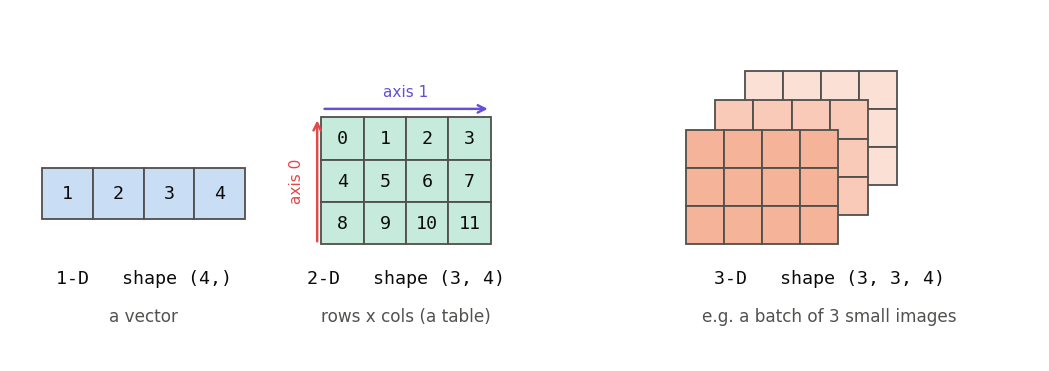

In [ ]:
a = np.array([[1, 2, 3],
              [4, 5, 6]])

print(a)
print("shape:", a.shape)     # (rows, cols)
print("ndim :", a.ndim)      # number of axes
print("dtype:", a.dtype)     # type of every element
print("size :", a.size)      # total number of elements

In [ ]:
print(np.zeros((2, 3)))
print(np.ones(4))
print(np.full((2, 2), 7.0))
print(np.eye(3))                         # identity matrix
print(np.arange(0, 10, 2))               # like range
print(np.linspace(0, 1, 5))              # 5 evenly spaced points

In [ ]:
rng = np.random.default_rng(seed=0)      # seed -> reproducible randomness
print(rng.random((2, 3)))                # uniform in [0, 1)
print(rng.standard_normal((2, 3)))       # normal(0, 1), like randn in MATLAB
print(rng.integers(0, 10, size=5))       # random integers (e.g. fake labels)

<div dir="rtl" style="direction: rtl; text-align: right;">

### dtype

| dtype | کاربرد |
|---|---|
| `float64` | پیش‌فرض NumPy |
| `float32` | پیش‌فرض شبکه‌های عصبی (نصف حافظه) |
| `int64` | برچسب کلاس‌ها |
| `uint8` | پیکسل تصویر (۰ تا ۲۵۵) |
| `bool` | ماسک |

با `.astype()` نوع را عوض می‌کنیم. (جلسه‌ی ۳ می‌بینیم که ناهماهنگی `float64` و `float32` یکی از خطاهای رایج PyTorch است.)

</div>

In [ ]:
img_uint8 = np.array([0, 128, 255], dtype=np.uint8)
img_float = img_uint8.astype(np.float32) / 255     # the usual "ToTensor" scaling to [0, 1]
print(img_uint8.dtype, img_float.dtype, img_float)

<div dir="rtl" style="direction: rtl; text-align: right;">

**برای کسانی که از متلب می‌آیند**

| | متلب | NumPy |
|---|---|---|
| شروع اندیس | از ۱ | **از ۰** |
| عنصر آخر | `x(end)` | `x[-1]` |
| بازه | `x(2:4)` شامل ۴ | `x[1:4]` **بدون** ۴ |
| ضرب عنصر به عنصر | `A .* B` | `A * B` |
| ضرب ماتریسی | `A * B` | `A @ B` |
| ترانهاده | `A'` | `A.T` |
| ابعاد | `size(A)` | `A.shape` |
| کپی با `=` | کپی واقعی | **فقط اسم جدید** (جلسه‌ی ۱) |

### اندیس‌گذاری و برش

مثل لیست است، فقط برای هر بُعد یک اندیس می‌دهید و با `,` جدا می‌کنید: `m[سطر, ستون]`. `:` یعنی «همه».

</div>

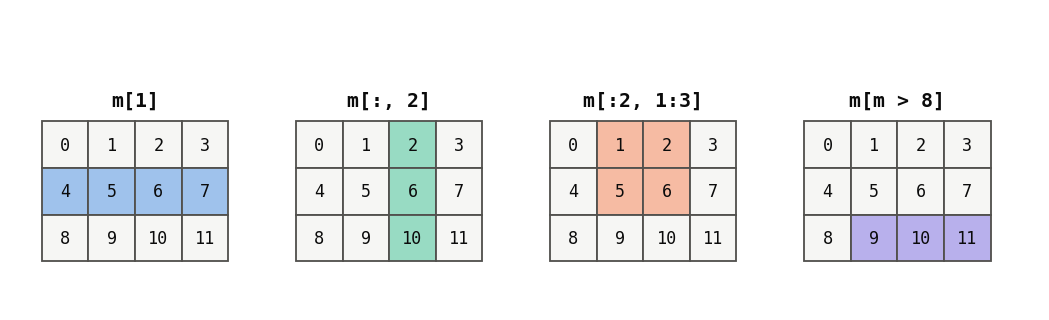

In [ ]:
m = np.arange(12).reshape(3, 4)
print(m)
print("m[0, 1]    =", m[0, 1])        # row 0, col 1
print("m[1]       =", m[1])           # whole row 1
print("m[:, 2]    =", m[:, 2])        # whole column 2
print("m[:2, 1:3] =\n", m[:2, 1:3])   # rows 0-1, cols 1-2
print("m[-1, -1]  =", m[-1, -1])      # last element

<div dir="rtl" style="direction: rtl; text-align: right;">

### ماسک بولی

یک شرط روی آرایه، یک آرایه‌ی `bool` هم‌اندازه می‌دهد. با آن می‌شود عنصرها را **بدون حلقه و بدون if** انتخاب کرد.

</div>

In [ ]:
scores = np.array([0.2, 0.9, 0.4, 0.7])
mask = scores > 0.5
print(mask)
print(scores[mask])
print("fraction above 0.5:", mask.mean())     # True counts as 1

scores[scores < 0.5] = 0                       # set by condition
print(scores)

print(np.where(scores > 0, 1, -1))             # if/else on every element

<div dir="rtl" style="direction: rtl; text-align: right;">

### برش در NumPy کپی نیست، view است

همان داستان جلسه‌ی ۱. برش‌زدن آرایه یک **پنجره (view)** روی همان حافظه می‌دهد. اگر view را عوض کنید، آرایه‌ی اصلی هم عوض می‌شود. کپی مستقل می‌خواهید؟ `.copy()`.

</div>

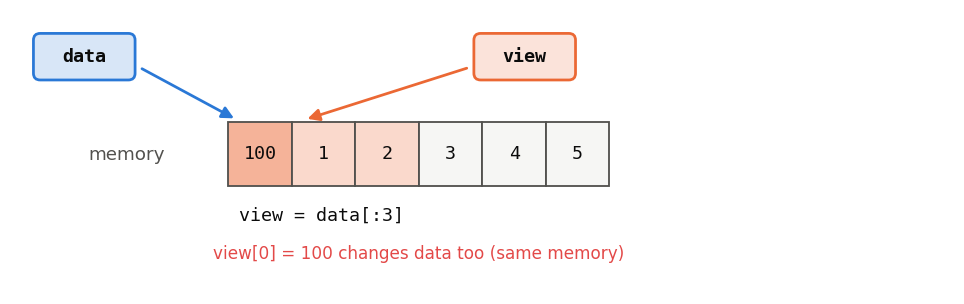

In [ ]:
data = np.arange(6)
view = data[:3]              # a window onto the same memory
view[0] = 100
print("data:", data)         # the original changed!

data = np.arange(6)
safe = data[:3].copy()       # an independent copy
safe[0] = 100
print("data:", data)

<div dir="rtl" style="direction: rtl; text-align: right;">

### عملیات عنصر به عنصر

عملگرها روی کل آرایه کار می‌کنند و همان dunderهای بخش ۱ هستند: `a + b` یعنی `a.__add__(b)`. همان `Vector` خودمان است، فقط سریع‌تر و کامل‌تر.

</div>

In [ ]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([10.0, 20.0, 30.0])

print(a + b, a.__add__(b))
print(a * b)                 # element-wise  (MATLAB: a .* b)
print(a @ b)                 # dot product   -> a.__matmul__(b)
print(a ** 2)
print(np.exp(a), np.log(a), np.sqrt(a))      # math functions work on the whole array
print(np.maximum(a - 2, 0))  # ReLU in one line!

<div dir="rtl" style="direction: rtl; text-align: right;">

### `axis`: روی کدام بُعد؟

تابع‌هایی مثل `sum`، `mean`، `max`، `argmax` یک آرگومان `axis` می‌گیرند. `axis` یعنی بُعدی که **جمع می‌شود و از بین می‌رود**.

</div>

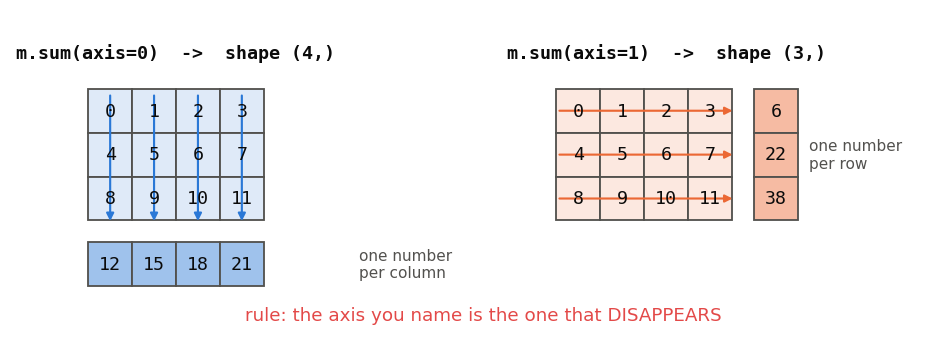

In [ ]:
m = np.arange(12).reshape(3, 4)
print(m)
print("sum all   :", m.sum())
print("sum axis=0:", m.sum(axis=0), m.sum(axis=0).shape)
print("sum axis=1:", m.sum(axis=1), m.sum(axis=1).shape)
print("mean axis=0:", m.mean(axis=0))

<div dir="rtl" style="direction: rtl; text-align: right;">

**مثال واقعی:** خروجی شبکه برای ۳ نمونه و ۴ کلاس، یک ماتریس `(3, 4)` است. «کلاس پیش‌بینی‌شده»ی هر نمونه = اندیس بزرگ‌ترین نمره در **هر سطر** = `argmax(axis=1)`. در PyTorch اسم `axis` می‌شود `dim`: `logits.argmax(dim=1)`.

</div>

In [ ]:
logits = np.array([[0.1, 2.0, 0.3, 0.0],
                   [1.5, 0.2, 0.1, 0.9],
                   [0.0, 0.1, 0.2, 3.0]])
labels = np.array([1, 0, 2])

preds = logits.argmax(axis=1)
print("predicted:", preds)
print("correct  :", preds == labels)
print("accuracy :", (preds == labels).mean())

<div dir="rtl" style="direction: rtl; text-align: right;">

### reshape

تعداد عنصرها ثابت می‌ماند، فقط چیدمان عوض می‌شود. `-1` یعنی «این بُعد را خودت حساب کن».

</div>

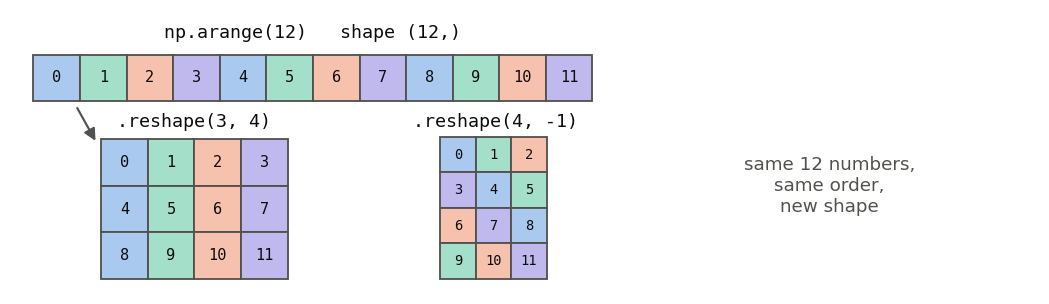

In [ ]:
x = np.arange(12)
print(x.reshape(3, 4))
print(x.reshape(4, -1).shape)            # -1 -> 12 / 4 = 3

images = np.zeros((32, 28, 28))          # a batch of 32 gray images
flat = images.reshape(32, -1)            # -1 -> 28*28 = 784 : ready for a Linear layer
print(images.shape, "->", flat.shape)

v = np.arange(3)
print(v.shape, v.reshape(3, 1).shape, v[:, None].shape, v[None, :].shape)   # None adds an axis

In [ ]:
# Joining arrays
a, b = np.ones((2, 3)), np.zeros((2, 3))
print(np.concatenate([a, b], axis=0).shape)   # glue along an existing axis
print(np.stack([a, b]).shape)                 # create a NEW axis (like making a batch)

<div dir="rtl" style="direction: rtl; text-align: right;">

### broadcasting

وقتی shape دو آرایه یکی نیست، NumPy سعی می‌کند آرایه‌ی کوچک‌تر را «کش بدهد» تا هم‌اندازه شوند (بدون کپی واقعی در حافظه).

**قانون:** shapeها را **از سمت راست** زیر هم بنویسید. هر جفت بُعد باید یا **برابر** باشند یا یکی‌شان **۱** باشد (یا اصلاً وجود نداشته باشد).

</div>

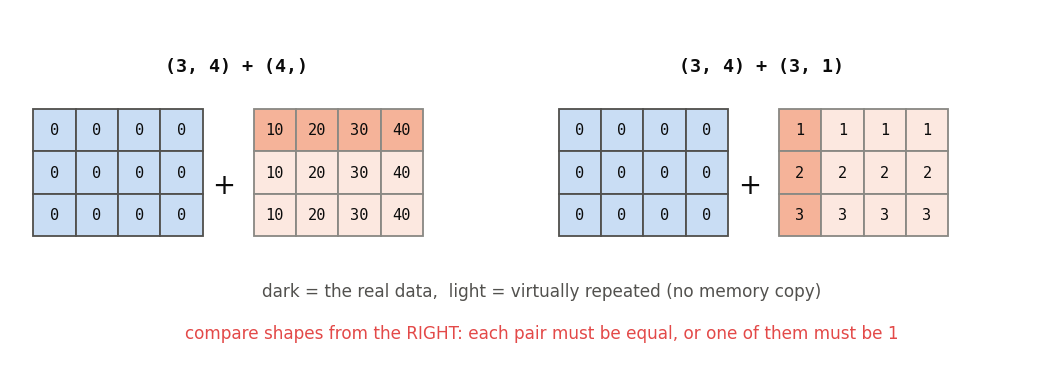

<div dir="rtl" style="direction: rtl; text-align: right;">

| A | B | نتیجه |
|---|---|---|
| `(3, 4)` | `()` عدد | `(3, 4)` |
| `(3, 4)` | `(4,)` | `(3, 4)` |
| `(3, 4)` | `(3, 1)` | `(3, 4)` |
| `(3, 1)` | `(1, 4)` | `(3, 4)` |
| `(3, 4)` | `(3,)` | **خطا** (۴ با ۳ نمی‌خواند) |

</div>

In [ ]:
X = np.zeros((3, 4), dtype=int)
print(X + np.array([10, 20, 30, 40]))        # (3,4) + (4,)   -> added to every row
print(X + np.array([[1], [2], [3]]))         # (3,4) + (3,1)  -> added to every column

try:
    X + np.array([1, 2, 3])                  # (3,4) + (3,)
except ValueError as e:
    print("ValueError:", e)

In [ ]:
# Typical use: normalize every feature (column) with its own mean and std
rng = np.random.default_rng(0)
X = rng.normal(loc=[0, 50, -3], scale=[1, 10, 0.1], size=(1000, 3))

X_norm = (X - X.mean(axis=0)) / X.std(axis=0)    # (1000,3) op (3,)
print("mean:", X_norm.mean(axis=0).round(3))
print("std :", X_norm.std(axis=0).round(3))

<div dir="rtl" style="direction: rtl; text-align: right;">

**تله‌ی خطرناک broadcasting.** اینجا خطا نمی‌گیرید، فقط **جواب غلط** می‌گیرید. این باگ در محاسبه‌ی loss خیلی رایج است: خروجی مدل `(N, 1)` است و برچسب‌ها `(N,)`.

</div>

In [ ]:
y_pred = np.array([[1.0], [2.0], [3.0]])     # shape (3, 1)
y_true = np.array([1.0, 2.0, 3.0])           # shape (3,)

diff = y_pred - y_true                       # (3,1) - (3,) -> (3,3) !!!
print(diff.shape)
print("wrong MSE:", (diff ** 2).mean())      # should be 0

diff = y_pred.reshape(-1) - y_true           # make the shapes match first
print("right MSE:", (diff ** 2).mean())

<div dir="rtl" style="direction: rtl; text-align: right;">

### ضرب ماتریسی: یک لایه‌ی شبکه‌ی عصبی

یک لایه‌ی خطی (fully connected) یعنی `Y = X @ W + b`. قانون shape در ضرب ماتریسی: `(N, in) @ (in, out) -> (N, out)`؛ دو عدد وسطی باید برابر باشند.

</div>

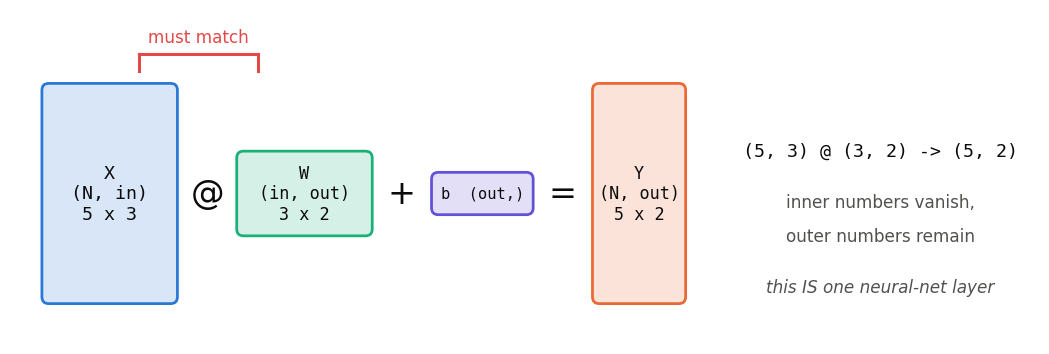

In [ ]:
rng = np.random.default_rng(0)

X = rng.standard_normal((5, 3))      # 5 samples, 3 features
W = rng.standard_normal((3, 2))      # 3 inputs -> 2 neurons
b = np.zeros(2)

Y = X @ W + b                        # matmul + broadcasting
print(X.shape, "@", W.shape, "+", b.shape, "->", Y.shape)

try:
    W @ X
except ValueError as e:
    print("ValueError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** یک شبکه‌ی دولایه با NumPy: ورودی `X` با shape `(5, 3)`، لایه‌ی اول ۳ ← ۴ با ReLU (`np.maximum(..., 0)`)، لایه‌ی دوم ۴ ← ۲. shape خروجی هر لایه را چاپ کنید.

</div>

In [ ]:
# your code here

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۵ — Matplotlib

در دیپ لرنینگ همیشه باید **ببینید**: منحنی loss، داده‌ها، تصویرها، خطاهای مدل. Matplotlib کتابخانه‌ی استاندارد رسم در پایتون است.

### آناتومی یک نمودار

- **`fig`** ← کل پنجره/تصویر.
- **`ax`** ← یک ناحیه‌ی رسم داخل `fig`. یک `fig` می‌تواند چند `ax` داشته باشد.
- همه‌ی چیزها (خط، عنوان، برچسب محور، legend) با متدهای `ax` اضافه می‌شوند.

شکل پیشنهادی شروع هر نمودار: `fig, ax = plt.subplots()`.

</div>

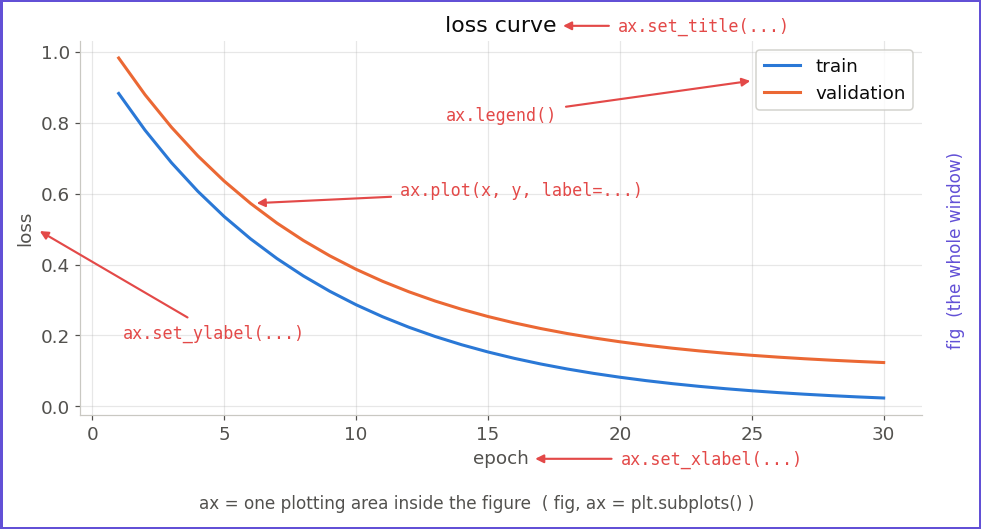

In [ ]:
import matplotlib.pyplot as plt

epochs = np.arange(1, 31)
train_loss = np.exp(-epochs / 8)
val_loss = np.exp(-epochs / 8) + 0.1

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, train_loss, label="train")
ax.plot(epochs, val_loss, "--", label="validation")      # "--" = dashed line
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("loss curve")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### scatter: نقاط داده

`c=` رنگ هر نقطه را از روی یک آرایه تعیین می‌کند (مثلاً برچسب کلاس) و `cmap` نقشه‌ی رنگ است.

</div>

In [ ]:
rng = np.random.default_rng(0)
pts = rng.standard_normal((200, 2))
labels = (pts[:, 0] * pts[:, 1] > 0).astype(int)          # a XOR-like pattern

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(pts[:, 0], pts[:, 1], c=labels, cmap="bwr", edgecolors="k", s=25)
ax.set_title("scatter: two classes")
ax.set_aspect("equal")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### hist: توزیع مقادیر

برای دیدن توزیع وزن‌ها، گرادیان‌ها یا پیکسل‌ها.

</div>

In [ ]:
weights = rng.standard_normal(5000) * 0.1

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(weights, bins=50)
ax.set_title("distribution of 5000 random weights")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### imshow: آرایه‌ی دوبعدی به‌عنوان تصویر

تصویر سیاه‌وسفید برای کامپیوتر فقط یک ماتریس عدد است. `imshow` هر عدد را به یک رنگ تبدیل می‌کند.

</div>

In [ ]:
digit = np.zeros((8, 8))
digit[1:7, 3:5] = 1          # a "1" drawn with slicing
digit[1:3, 2] = 1
digit[6, 2:6] = 1

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(digit, cmap="gray")
axes[0].set_title("as an image")
axes[1].imshow(digit, cmap="viridis")
for i in range(8):
    for j in range(8):
        axes[1].text(j, i, int(digit[i, j]), ha="center", va="center", color="w", fontsize=8)
axes[1].set_title("it is just numbers")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### subplots: چند نمودار کنار هم

`plt.subplots(rows, cols)` یک آرایه از `ax`ها برمی‌گرداند. با `axes.flat` می‌شود روی همه‌شان حلقه زد. `fig.savefig` نمودار را ذخیره می‌کند (برای گزارش و مقاله).

</div>

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(rng.random((8, 8)), cmap="gray")
    ax.set_title(f"sample {k}")
    ax.axis("off")                       # hide ticks for images
fig.suptitle("a grid of random 'images'")
plt.tight_layout()
fig.savefig("grid.png", dpi=100)
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** تابع‌های `sigmoid`، `tanh` و `relu` را روی `x = np.linspace(-5, 5, 200)` حساب کنید و هر سه را در یک نمودار با legend رسم کنید. ($\sigma(x) = \frac{1}{1+e^{-x}}$، از `np.tanh` و `np.maximum` استفاده کنید.)

</div>

In [ ]:
x = np.linspace(-5, 5, 200)
# your code here

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۶ — پرسپترون از صفر

حالا همه‌چیز را کنار هم می‌گذاریم و پرسپترون (همان `PerceptronClass.m` درس) را با پایتون می‌نویسیم.

پرسپترون یک نورون است: `y = sign(x · w + b)`. قانون یادگیری: نمونه‌ها را یکی‌یکی نگاه کن و اگر نمونه‌ای **اشتباه** دسته‌بندی شد:

- `w ← w + η · t · x`
- `b ← b + η · t`

که `t` برچسب درست (۱+ یا ۱-) و `η` نرخ یادگیری است.

</div>

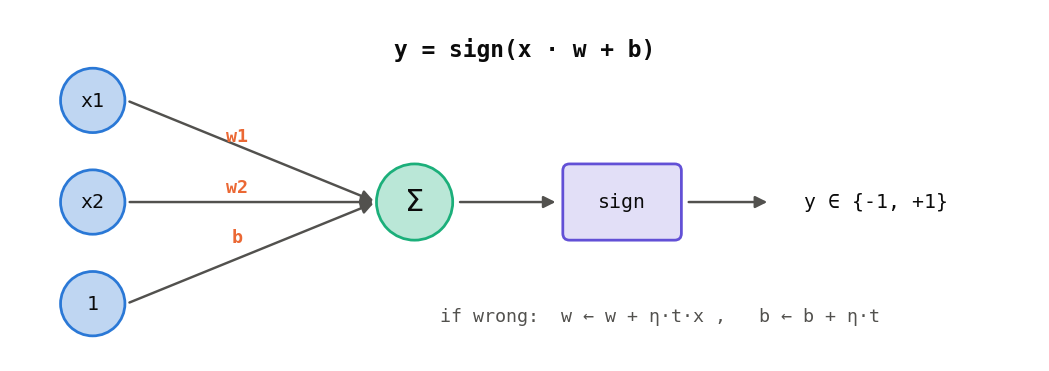

<div dir="rtl" style="direction: rtl; text-align: right;">

### ساخت داده (معادل `DataCreate.m`)

</div>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def make_data(n, centers, R, seed=0):
    """n uniform points in a square of half-width R around every center."""
    rng = np.random.default_rng(seed)
    X, labels = [], []
    for i, center in enumerate(centers):
        points = rng.uniform(-R, R, size=(n, 2)) + center    # broadcasting: (n,2) + (2,)
        X.append(points)
        labels.append(np.full(n, i))
    return np.concatenate(X), np.concatenate(labels)

centers = np.array([[1, 1], [-1, -1]])
X, labels = make_data(n=50, centers=centers, R=0.75)

T = np.where(labels == 0, 1, -1)         # class 0 -> +1, class 1 -> -1
X = X / np.abs(X).max()                  # normalization, same as the MATLAB code

print("X:", X.shape, "| T:", T.shape, "| classes:", np.unique(T))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=T, cmap="bwr", edgecolors="k")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Dataset")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### کلاس پرسپترون

به چیزهایی که از قبل آمده دقت کنید: `__init__` برای ساخت وزن‌ها، `__call__` برای اینکه بنویسیم `model(X)`، عملگر `@` برای ضرب داخلی، `+=` برای آپدیت درجا، `zip` برای راه‌رفتن هم‌زمان روی نمونه‌ها و برچسب‌ها، و ماسک بولی برای شمردن خطاها.

</div>

In [ ]:
class Perceptron:
    def __init__(self, n_features, eta=0.5, seed=0):
        rng = np.random.default_rng(seed)
        self.w = rng.standard_normal(n_features)
        self.b = rng.standard_normal()
        self.eta = eta

    def __call__(self, X):
        return np.sign(X @ self.w + self.b)      # works for one sample or a whole batch

    def fit(self, X, T, epochs=10):
        history = []
        for epoch in range(epochs):
            for x, t in zip(X, T):               # one sample at a time
                if self(x) != t:                 # misclassified -> update
                    self.w += self.eta * t * x
                    self.b += self.eta * t
            errors = int((self(X) != T).sum())   # boolean mask + sum
            history.append(errors)
            print(f"epoch {epoch + 1}: {errors} errors")
            if errors == 0:
                break
        return history

model = Perceptron(n_features=2, eta=0.5)
print("before training:", int((model(X) != T).sum()), "errors")
history = model.fit(X, T, epochs=10)
print("w =", model.w, "| b =", model.b)

<div dir="rtl" style="direction: rtl; text-align: right;">

### رسم مرز تصمیم

یک شبکه‌ی ۳۰۰×۳۰۰ نقطه روی صفحه می‌سازیم، مدل را **یک‌جا** (بدون حلقه) روی همه‌شان اجرا می‌کنیم و صفحه را بر اساس پیش‌بینی رنگ می‌کنیم.

</div>

In [ ]:
def plot_boundary(model, X, T, title=""):
    """Colour the plane by the model's prediction, then draw the data on top."""
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
    grid = np.column_stack([xx.ravel(), yy.ravel()])     # (90000, 2): every point of the plane
    zz = model(grid).reshape(xx.shape)                   # one vectorized call, no loop

    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="bwr")
    ax.scatter(X[:, 0], X[:, 1], c=T, cmap="bwr", edgecolors="k")
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title)
    plt.show()

plot_boundary(model, X, T, title="Perceptron decision boundary")

<div dir="rtl" style="direction: rtl; text-align: right;">

### جایی که پرسپترون کم می‌آورد: XOR

چهار خوشه می‌سازیم که خوشه‌های روبه‌روی هم هم‌کلاس‌اند. هیچ **خط راستی** نمی‌تواند این دو کلاس را جدا کند، پس پرسپترون هر چقدر هم آموزش ببیند به صفر خطا نمی‌رسد.

</div>

In [ ]:
centers = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1]])
X_xor, labels = make_data(n=50, centers=centers, R=0.75)

T_xor = np.where(labels < 2, 1, -1)      # clusters 0,1 -> +1   clusters 2,3 -> -1
X_xor = X_xor / np.abs(X_xor).max()

model_xor = Perceptron(n_features=2, eta=0.5)
history = model_xor.fit(X_xor, T_xor, epochs=10)

plot_boundary(model_xor, X_xor, T_xor, title="Perceptron on XOR: fails")

<div dir="rtl" style="direction: rtl; text-align: right;">

راه‌حل: چند لایه نورون با تابع فعال‌سازی غیرخطی، یعنی **MLP**. ولی برای آموزش آن به گرادیان نیاز داریم و حساب‌کردن دستی گرادیان برای شبکه‌های بزرگ عملی نیست.

**جلسه‌ی ۳:** PyTorch گرادیان را خودش حساب می‌کند. همین مسئله‌ی XOR را با MLP حل می‌کنیم و بعد سراغ MNIST و CNN می‌رویم.

---
## تمرین

1. **dunder:** به کلاس `Vector` متدهای `__sub__`، `__eq__` و `__rmul__` را اضافه کنید.
2. **generator:** تابع `batches` را طوری تغییر دهید که آرگومان `drop_last` بگیرد و اگر `True` بود، batch آخرِ ناقص را برنگرداند.
3. **Dataset:** کلاس `MyDataset` را طوری تغییر دهید که یک آرگومان `transform` (یک تابع) بگیرد و در `__getitem__` روی `x` اعمالش کند. این دقیقاً همان کاری است که `torchvision` می‌کند (جلسه‌ی ۳).
4. **broadcasting:** آرایه‌ای با shape برابر `(100, 3)` بسازید و بدون حلقه، فاصله‌ی اقلیدسی هر سطر را از سطر اول حساب کنید.
5. **softmax:** تابع `softmax(logits)` بنویسید که برای ماتریس `(N, C)` در هر سطر $\frac{e^{z_i}}{\sum_j e^{z_j}}$ را حساب کند. جمع هر سطر خروجی باید ۱ شود. (راهنمایی: `axis=1` و `keepdims=True`.)
6. **Matplotlib:** برای پرسپترون، تعداد خطا در هر epoch (`history`) را رسم کنید.
7. **پرسپترون:** `eta` را ۰٫۰۱ و ۵ بگذارید و تعداد epoch لازم برای همگرایی را مقایسه کنید. بعد `R` را در `make_data` به ۱٫۲ برسانید (خوشه‌ها روی هم می‌افتند) و ببینید چه می‌شود.

</div>